# 9. Bayesian Optimization (Bayes Optimallaşdırması) ilə Hiperparametrlərin Tənzimlənməsi

Maşın öyrənməsi modellərinin (xüsusilə **XGBoost**, **LightGBM**, **CatBoost**, **AdaBoost** və Dərin Neyron Şəbəkələri kimi mürəkkəb alqoritmlərin) proqnozlaşdırma qabiliyyəti seçilmiş **hiperparametrlərdən** birbaşa asılıdır. Modelin daxili parametrləri (məsələn, ağacların yarpaq çəkiləri $w_j$) təlim zamanı qradiyent əsasında avtomatik öyrənildiyi halda, **hiperparametrlər** (məsələn, ağacların sayı `n_estimators`, öyrənmə sürəti `learning_rate`, maksimum dərinlik `max_depth`, sütun seçimi payı `colsample_bytree`) təlimdən əvvəl tədqiqatçı tərəfindən təyin edilməlidir.

---

### Bayes Optimallaşdırmasının Riyazi Əsasları

Məqsədimiz hesablama baxımından bahalı olan və analitik törəməsi ($\nabla_x f(x)$) bilinməyən "qara-qutu" (*black-box*) hədəf funksiyasını (məsələn, doğrulama dəsti üzrə $\text{Adjusted } R^2$ göstəricisini) maksimallaşdıran optimal $x^*$ hiperparametr vektorunu tapmaqdır:

$\displaystyle x^* = \arg\max_{x \in \mathcal{X}} f(x)$

Bayes Optimallaşdırması **Bayes teoreminə** ($P(f \mid \mathcal{D}_{1:t}) \propto P(\mathcal{D}_{1:t} \mid f)\,P(f)$) əsaslanır və iki əsas riyazi komponentdən ibarətdir:

#### A) Surroqat Model (Surrogate Model) — Qauss Prosesi (Gaussian Process, GP)
Həqiqi $f(x)$ funksiyasını hər nöqtədə hesablamaq (hər dəfə yeni XGBoost modelini sıfırdan öyrətmək) baha başa gəldiyi üçün, keçmiş müşahidələr çoxluğu $\mathcal{D}_{1:t} = \{(x_i, y_i)\}_{i=1}^{t}$ əsasında $f(x)$ üzərində ehtimal paylanması qurulur:

$\displaystyle f(x) \sim \mathcal{GP}\big(m(x),\, k(x, x')\big)$

Burada $m(x)$ orta funksiya (adətən $0$), $k(x, x')$ isə iki hiperparametr nöqtəsi arasındakı oxşarlığı ölçən nüvə (*kernel* / kovariasiya, standart olaraq **Matérn $\nu=5/2$** nüvəsi) funksiyasıdır:

$\displaystyle k_{\text{Matérn}}(x, x') = \sigma_f^2 \left(1 + \frac{\sqrt{5}\,r}{\ell} + \frac{5\,r^2}{3\,\ell^2}\right) \exp\left(-\frac{\sqrt{5}\,r}{\ell}\right), \quad r = \|x - x'\|_2$

Qauss Prosesi istənilən yeni $x$ namizəd nöqtəsi üçün analitik **aposterior (posterior) normal paylanma** verir:

$\displaystyle P\big(f(x) \mid \mathcal{D}_{1:t}, x\big) = \mathcal{N}\big(\mu_t(x),\, \sigma_t^2(x)\big)$

* **$\mu_t(x) = \mathbf{k}_*^\top (\mathbf{K} + \sigma_n^2 \mathbf{I})^{-1} \mathbf{y}$ (Gözlənilən orta qiymət):** Həmin nöqtədə gözlənilən model performansı.
* **$\sigma_t^2(x) = k(x, x) - \mathbf{k}_*^\top (\mathbf{K} + \sigma_n^2 \mathbf{I})^{-1} \mathbf{k}_*$ (Dispersiya / Qeyri-müəyyənlik):** Həmin bölgənin nə dərəcədə az araşdırıldığını göstərir.

#### B) Qərar / Seçim Funksiyası (Acquisition Function — $\alpha(x)$)
Növbəti iterasiyada hansı $x_{t+1}$ nöqtəsinin sınaqdan keçiriləcəyini müəyyən edən köməkçi funksiyadır:

$\displaystyle x_{t+1} = \arg\max_{x \in \mathcal{X}} \alpha(x \mid \mathcal{D}_{1:t})$

Bu funksiya iki ziddiyyətli hədəf arasında optimal balans yaradır:
1. **Exploitation (İstismar):** $\mu_t(x)$-in yüksək olduğu (artıq yüksək nəticə verdiyi məlum olan) bölgələrdə dəqiqləşdirici axtarış etmək.
2. **Exploration (Kəşfiyyat):** $\sigma_t(x)$-in böyük olduğu (hələ yoxlanılmamış, lakin qlobal maksimumu gizlətmə potensialı olan) naməlum bölgələri kəşf etmək.

Ən geniş yayılmış Acquisition funksiyaları:
* **Upper Confidence Bound (UCB)** (`bayes_opt` kitabxanasında standart olaraq istifadə olunur, $\kappa \approx 2.576$):
  $\displaystyle \alpha_{\text{UCB}}(x) = \mu_t(x) + \kappa \cdot \sigma_t(x)$
* **Expected Improvement (EI):** İndiyə qədər tapılmış ən yaxşı nəticə $f(x^+)$ üzərində gözlənilən artımı maksimallaşdırır:
  $\displaystyle \alpha_{\text{EI}}(x) = \mathbb{E}\Big[\max\big(0,\, f(x) - f(x^+)\big)\Big] = (\mu_t(x) - f(x^+) - \xi)\,\Phi(Z) + \sigma_t(x)\,\phi(Z)$

## 1. Lazımi Kitabxanaların İmport Edilməsi

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from bayes_opt import BayesianOptimization

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 110

## 2. Məlumatların Yüklənməsi və İlkin Kəşfiyyat Təhlili (EDA)

Tədqiqatda ABŞ-ın Vaşinqton ştatının **King County** bölgəsində (Sietl və ətrafı) 2014–2015-ci illərdə satılmış **21,613** evin texniki-coğrafi xüsusiyyətlərini və satış qiymətlərini (`price`) əks etdirən **`kc_housing.csv`** verilənlər bazasından istifadə olunur.

**Verilənlər Bazasındakı Dəyişənlərin Təsviri:**
* **`date`:** Evin satıldığı tarix (ISO zaman damğası formatında).
* **`price` (Hədəf dəyişən — $y$):** Evin satış qiyməti (ABŞ dolları ilə).
* **`bedrooms` / `bathrooms` / `floors`:** Yataq otaqlarının, vanna otaqlarının və mərtəbələrin sayı.
* **`sqft_living` / `sqft_lot` / `sqft_above` / `sqft_basement`:** Yaşayış sahəsi, həyət/torpaq sahəsi, yerüstü mərtəbələrin sahəsi və zirzəmi sahəsi (kvadrat fut ilə).
* **`waterfront`:** Evin dəniz/göl sahilində yerləşib-yerləşməməsi (`True` / `False`).
* **`view` (0–4):** Evin mənzərə keyfiyyəti indeksi.
* **`condition` (1–5):** Evin ümumi fiziki-texniki vəziyyəti.
* **`grade` (1–13):** King County qiymətləndirmə sisteminə görə tikinti və dizayn keyfiyyəti dərəcəsi.
* **`yr_built` / `yr_renovated`:** Evin inşa edildiyi il və əsaslı təmir olunduğu il.
* **`zipcode` / `lat` / `long`:** Poçt indeksi, şimal enliyi (`lat`) və qərb uzunluğu (`long`) koordinatları.
* **`sqft_living15` / `sqft_lot15`:** Ən yaxın 15 qonşu evin orta yaşayış və torpaq sahəsi.

In [2]:
df = pd.read_csv('kc_housing.csv')
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-12T22:00:00Z,221900,3,1.00,1180,5650,1.0,False,0,3,7,1180,NaN,1955,NaN,98178,47.5112,-122.257,1340,5650
1,2014-12-08T23:00:00Z,538000,3,2.25,2570,7242,2.0,False,0,3,7,2170,400.0,1951,1991.0,98125,47.7210,-122.319,1690,7639
2,2015-02-24T23:00:00Z,180000,2,1.00,770,10000,1.0,False,0,3,6,770,NaN,1933,NaN,98028,47.7379,-122.233,2720,8062
3,2014-12-08T23:00:00Z,604000,4,3.00,1960,5000,1.0,False,0,5,7,1050,910.0,1965,NaN,98136,47.5208,-122.393,1360,5000
4,2015-02-17T23:00:00Z,510000,3,2.00,1680,8080,1.0,False,0,3,8,1680,NaN,1987,NaN,98074,47.6168,-122.045,1800,7503


### Verilənlərin Tipləri və Boş Dəyərlərin (Missing Values) Analizi

1. **`df.info()`**: Cədvəldə 21,613 sətir və 20 sütun var.
2. **`waterfront` sütununun çevrilməsi**: `bool` tipində olan `waterfront` dəyişəni kateqorik kodlaşdırıcı (`OneHotEncoder`) tərəfindən problemsiz emal edilməsi üçün `object` tipinə çevrilir.
3. **Boş Dəyərlər (`NaN`)**:
   * `yr_renovated`: **20,699** boş dəyər (evlərin əksəriyyəti heç vaxt əsaslı təmir olunmayıb).
   * `sqft_basement`: **13,126** boş dəyər (zirzəmisi olmayan evlər).
   * **XGBoost-un üstünlüyü (`Sparsity-Aware Split Finding`):** Ənənəvi xətti modellərdən fərqli olaraq, XGBoost hər bir ağac düyünündə `NaN` dəyərlər üçün həm sol, həm də sağ budağa getmə halında itki funksiyasının azalmasını (*Gain*) hesablayır və `NaN` dəyərləri avtomatik olaraq ən optimal budağa yönləndirir.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           21613 non-null  object 
 1   price          21613 non-null  int64  
 2   bedrooms       21613 non-null  int64  
 3   bathrooms      21613 non-null  float64
 4   sqft_living    21613 non-null  int64  
 5   sqft_lot       21613 non-null  int64  
 6   floors         21613 non-null  float64
 7   waterfront     21613 non-null  bool   
 8   view           21613 non-null  int64  
 9   condition      21613 non-null  int64  
 10  grade          21613 non-null  int64  
 11  sqft_above     21613 non-null  int64  
 12  sqft_basement  8487 non-null   float64
 13  yr_built       21613 non-null  int64  
 14  yr_renovated   914 non-null    float64
 15  zipcode        21613 non-null  int64  
 16  lat            21613 non-null  float64
 17  long           21613 non-null  float64
 18  sqft_l

In [4]:
df['waterfront'] = df['waterfront'].astype('object')

In [5]:
target = 'price'

In [6]:
# Sütunlar üzrə boş (NaN) dəyərlərin sayının azalan sıra ilə yoxlanılması
df.isna().sum().sort_values(ascending=False)

yr_renovated     20699
sqft_basement    13126
date                 0
price                0
sqft_living15        0
long                 0
lat                  0
zipcode              0
yr_built             0
sqft_above           0
grade                0
condition            0
view                 0
waterfront           0
floors               0
sqft_lot             0
sqft_living          0
bathrooms            0
bedrooms             0
sqft_lot15           0
dtype: int64

### Təlim (Train) və Test Dəstlərinə Bölünmə

In [7]:
train, test = train_test_split(df, test_size=0.2, random_state=123)

## 3. Baza XGBoost Alqoritmasının Qurulması (Baseline Model)

In [8]:
# Müstəqil dəyişənlərin (feature_cols), kateqorik və ədədi sütunların ayrılması
feature_cols = [c for c in df.columns if c != target]
categorical_cols = ['date', 'waterfront']
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

In [9]:
# Ön emal (Preprocessing) konveyeri:
# - Kateqorik sütunlar One-Hot Encoding ilə ikili vektorlara çevrilir (naməlum kateqoriyalar ignore edilir)
# - Ədədi sütunlar dəyişdirilmədən ('passthrough') modelə ötürülür
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ],
    remainder="drop",
)

In [10]:
# Standart (baza) hiperparametrlərlə XGBoost Reqressiya modelinin yaradılması
base_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=50,
    learning_rate=0.1,
    max_depth=4,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=123,
    n_jobs=-1
)

In [11]:
# Ön emal və baza modeli birləşdirən Pipeline
pipe = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", base_model)
])

In [12]:
# Təlim və test dəstləri üzrə X (əlamətlər) və y (hədəf) matrislərinin formalaşdırılması
X_train, y_train = train[feature_cols], train[target]
X_test,  y_test  = test[feature_cols],  test[target]

In [13]:
# Baza modelin təlim dəsti üzərində öyrədilməsi
pipe.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [14]:
# Test dəsti üzərində baza modelin proqnozlarının alınması
pred = pipe.predict(X_test)
pred

array([ 635859.3 ,  528316.75,  845228.8 , ...,  462386.06, 1053496.8 ,
       1117217.8 ], dtype=float32)

## 4. Reqressiya Metrikaları və $\text{Adjusted } R^2$

In [16]:
def adjusted_r2(y_true, y_pred, p):
    """Adjusted R2 hesablayan funksiya."""
    n = len(y_true)
    r2 = r2_score(y_true, y_pred)
    return 1.0 - (1.0 - r2) * (n - 1) / max(n - p - 1, 1)

# OneHotEncoder-dən sonra modelə daxil olan effektiv əlamətlərin sayı (369 tarix + 2 waterfront + 17 ədədi = 388)
p_effective = pipe.named_steps["model"].n_features_in_
p_effective

388

In [17]:
# Baza modelin keyfiyyət metrikalarının hesablanması
r2_base   = r2_score(y_test, pred)
adj_r2    = adjusted_r2(y_test.values, pred, p_effective)
mae       = mean_absolute_error(y_test, pred)
mse       = mean_squared_error(y_test, pred)
rmse      = np.sqrt(mse)

print(f"R2:          {r2_base:.4f}")
print(f"Adjusted R2: {adj_r2:.4f}")
print(f"MAE:         {mae:,.2f} $")
print(f"MSE:         {mse:,.2f}")
print(f"RMSE:        {rmse:,.2f} $")

R2:          0.8748
Adjusted R2: 0.8624
MAE:         79,036.24 $
MSE:         17,682,427,904.00
RMSE:        132,975.29 $


## 5. Bayesian Optimization ilə Optimal Hiperparametrlərin Tapılması

`BayesianOptimization` obyektinə iki əsas arqument ötürülür:
1. **Hədəf funksiyası (`f=train_eval`)**: Hiperparametrləri qəbul edən, modeli öyrədən və maksimallaşdırılacaq metrikanı ($\text{Adjusted } R^2$) qaytaran funksiya.
   * *Texniki detal:* Qauss Prosesi kəsilməz (*float*) ədədlərlə işlədiyi üçün `n_estimators` və `max_depth` kimi tam ədəd tələb edən hiperparametrlər funksiya daxilində `int(round(...))` ilə tam ədədə yuvarlaqlaşdırılır.
2. **Axtarış sərhədləri (`pbounds`)**: Hər bir hiperparametrin axtarılacağı aşağı və yuxarı sərhədlər:
   * `colsample_bytree`: $[0.1,\, 1.0]$
   * `n_estimators`: $[30,\, 500]$
   * `learning_rate`: $[0.01,\, 0.5]$
   * `max_depth`: $[2,\, 10]$

**`optimizer.maximize(init_points=5, n_iter=5)` parametrlərinin mənası:**
* **`init_points=5` (İlkin Kəşfiyyat / Random Exploration):** Qauss Prosesinin ilkin prior səthini formalaşdırmaq üçün hiperparametr fəzasında **5 təsadüfi nöqtə** yoxlanılır.
* **`n_iter=5` (Bayes Optimallaşdırması Addımları):** Surroqat model (GP) və Acquisition funksiyası əsasında hədəf funksiyasını maksimallaşdırma ehtimalı ən yüksək olan **5 ağıllı nöqtə** ardıcıl olaraq seçilir və sınaqdan keçirilir.

In [18]:
def train_eval(colsample_bytree, n_estimators, learning_rate, max_depth):
    """Bayes optimallaşdırması üçün hədəf (objective) funksiyası."""
    # Diskret (tam ədədli) hiperparametrlərin yuvarlaqlaşdırılması
    n_estimators = int(round(n_estimators))
    max_depth = int(round(max_depth))

    model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        max_depth=max_depth,
        subsample=1.0,
        colsample_bytree=colsample_bytree,
        random_state=123,
        n_jobs=-1
    )

    pipe_bo = Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", model)
    ])

    pipe_bo.fit(X_train, y_train)
    pred_val = pipe_bo.predict(X_test)

    p_eff = pipe_bo.named_steps["model"].n_features_in_
    adj = adjusted_r2(y_test.values, pred_val, p_eff)

    return adj

In [19]:
# Hiperparametrlərin axtarış fəzasının (aşağı və yuxarı sərhədlərin) təyin edilməsi
pbounds = {
    "colsample_bytree": (0.1, 1.0),
    "n_estimators":     (30, 500),
    "learning_rate":    (0.01, 0.5),
    "max_depth":        (2, 10)
}

In [20]:
# Bayes Optimallaşdırıcısının inisializasiyası (verbose=2 bütün iterasiyaları cədvəl şəklində çap edir)
optimizer = BayesianOptimization(
    f=train_eval,
    pbounds=pbounds,
    random_state=123,
    verbose=2
)

In [21]:
# 5 ilkin təsadüfi kəşfiyyat nöqtəsi (init_points=5) və 5 Bayes axtarışı addımı (n_iter=5)
optimizer.maximize(init_points=5, n_iter=5)

|   iter    |  target   | colsam... | n_esti... | learni... | max_depth |
-------------------------------------------------------------------------
| 1         | 0.8905333 | 0.7268222 | 164.48548 | 0.1211572 | 6.4105181 |
| 2         | 0.8656817 | 0.7475220 | 228.86003 | 0.4905744 | 7.4786379 |
| 3         | 0.8972218 | 0.5328387 | 214.29523 | 0.1781572 | 7.8323976 |
| 4         | 0.8908919 | 0.4947150 | 58.048611 | 0.2050416 | 7.9039632 |
| 5         | 0.8703424 | 0.2642425 | 112.46232 | 0.2704601 | 6.2546206 |
| 6         | 0.8579131 | 0.3906630 | 394.96641 | 0.3668456 | 6.5117517 |
| 7         | 0.8658756 | 0.4902896 | 160.77651 | 0.2907603 | 9.4000905 |
| 8         | 0.8788008 | 0.6695799 | 421.62942 | 0.2975691 | 9.1849961 |
| 9         | 0.8904856 | 0.9968211 | 205.92403 | 0.0587708 | 6.1953560 |
| 10        | 0.8220090 | 0.3520391 | 154.04810 | 0.4396716 | 8.8020914 |


### Optimal Hiperparametrlərin Seçilməsi və Yuvarlaqlaşdırılması

`optimizer.max` lüğəti ən yüksək `target` ($\text{Adjusted } R^2 = 0.8972$) nəticəsini verən **3-cü iterasiyanın** hiperparametrlərini saxlayır:
* `colsample_bytree`: $\approx 0.5328$ (hər ağacda sütunların $\approx 53.3\%$-i təsadüfi seçilir — bu, `388` sütunlu seyrək matrisdə ağacların həddindən artıq uyğunlaşmasının qarşısını alır).
* `n_estimators`: $214.295 \rightarrow 214$ ağac.
* `learning_rate`: $\approx 0.1782$.
* `max_depth`: $7.832 \rightarrow 8$ (daha dərin ağaclar coğrafi koordinatlar `lat`/`long` ilə `sqft_living` və `grade` arasındakı mürəkkəb qeyri-xətti əlaqələri daha yaxşı tutur).

In [22]:
# Ən yüksək nəticə verən hiperparametrlərin surətinin çıxarılması
best_params = optimizer.max["params"].copy()
best_params

{'colsample_bytree': 0.5328387113359249,
 'n_estimators': 214.29523355125076,
 'learning_rate': 0.17815722791392602,
 'max_depth': 7.832397659072333}

In [23]:
# Tam ədəd olmalı hiperparametrlərin yuvarlaqlaşdırılması
best_params["n_estimators"] = int(round(best_params["n_estimators"]))
best_params["max_depth"] = int(round(best_params["max_depth"]))
best_params

{'colsample_bytree': 0.5328387113359249,
 'n_estimators': 214,
 'learning_rate': 0.17815722791392602,
 'max_depth': 8}

## 6. Optimal Hiperparametrlərlə Yekun Modelləşdirmə və Qiymətləndirmə

Tapılmış optimal hiperparametrlərlə (`best_params`) yekun `XGBRegressor` modelini (`best_model`) qururuq, konveyeri (`pipe_best`) təlim dəsti üzərində öyrədirik və test dəsti üzərində proqnozları (`pred_best`) hesablayırıq.

In [24]:
# Optimal hiperparametrlərlə XGBoost modelinin qurulması
best_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=best_params["n_estimators"],
    learning_rate=best_params["learning_rate"],
    max_depth=best_params["max_depth"],
    subsample=1.0,
    colsample_bytree=best_params["colsample_bytree"],
    random_state=123,
    n_jobs=-1
)

In [25]:
# Yekun Pipeline-ın yaradılması
pipe_best = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", best_model)
])

In [26]:
# Optimal modelin təlim dəsti üzərində öyrədilməsi
pipe_best.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [27]:
# Test dəsti üzərində optimal modelin proqnozları
pred_best = pipe_best.predict(X_test)
pred_best

array([ 621684.7 ,  503594.66,  843692.56, ...,  412351.06, 1217774.2 ,
       1031455.1 ], dtype=float32)

In [28]:
# Optimal modelin keyfiyyət metrikalarının hesablanması
p_eff_best  = pipe_best.named_steps["model"].n_features_in_
r2_best     = r2_score(y_test, pred_best)
adj_r2_best = adjusted_r2(y_test.values, pred_best, p_eff_best)
mae_best    = mean_absolute_error(y_test, pred_best)
mse_best    = mean_squared_error(y_test, pred_best)
rmse_best   = np.sqrt(mse_best)

print(f"R2 (Best):          {r2_best:.4f}")
print(f"Adjusted R2 (Best): {adj_r2_best:.4f}")
print(f"MAE (Best):         {mae_best:,.2f} $")
print(f"MSE (Best):         {mse_best:,.2f}")
print(f"RMSE (Best):        {rmse_best:,.2f} $")

R2 (Best):          0.9064
Adjusted R2 (Best): 0.8972
MAE (Best):         66,335.58 $
MSE (Best):         13,211,403,264.00
RMSE (Best):        114,940.87 $


## 7. Baza Model ilə Bayes Optimallaşdırılmış Modelin Müqayisəsi və Vizuallaşdırılması

Aşağıdakı cədvəl və diaqramlar vasitəsilə:
1. **Baza XGBoost (`base_model`)** və **Bayes Optimallaşdırılmış XGBoost (`best_model`)** modellərinin bütün reqressiya metrikalarını ($R^2$, $\text{Adjusted } R^2$, $\text{MAE}$, $\text{RMSE}$) müqayisə edirik.
2. Bayes Optimallaşdırmasının 10 iterasiya ərzində hədəf funksiyasını ($\text{Adjusted } R^2$) necə araşdırdığını və maksimum nöqtəni tapdığını vizuallaşdırırıq.
3. Həqiqi ev qiymətləri (`y_test`) ilə proqnozlaşdırılmış qiymətlərin (`pred` vs `pred_best`) səpilmə diaqramını, qalıq xətaların (*residuals*) paylanmasını və **Ən Əhəmiyyətli 15 Əlaməti (Feature Importance)** təhlil edirik.

In [29]:
comparison_df = pd.DataFrame({
    "Metrika": ["R2", "Adjusted R2", "MAE ($)", "RMSE ($)"],
    "Baza XGBoost": [
        f"{r2_base:.4f}",
        f"{adj_r2:.4f}",
        f"{mae:,.2f}",
        f"{rmse:,.2f}"
    ],
    "Bayesian Tuned XGBoost": [
        f"{r2_best:.4f}",
        f"{adj_r2_best:.4f}",
        f"{mae_best:,.2f}",
        f"{rmse_best:,.2f}"
    ],
    "Fərq / Yaxşılaşma": [
        f"+{r2_best - r2_base:.4f}",
        f"+{adj_r2_best - adj_r2:.4f}",
        f"{mae_best - mae:,.2f} ({(mae_best - mae) / mae * 100:.1f}%)",
        f"{rmse_best - rmse:,.2f} ({(rmse_best - rmse) / rmse * 100:.1f}%)"
    ]
}).set_index("Metrika")

print("=== Baza XGBoost vs Bayesian Tuned XGBoost Müqayisə Cədvəli ===")
print(comparison_df)

=== Baza XGBoost vs Bayesian Tuned XGBoost Müqayisə Cədvəli ===
            Baza XGBoost Bayesian Tuned XGBoost    Fərq / Yaxşılaşma
Metrika                                                             
R2                0.8748                 0.9064              +0.0317
Adjusted R2       0.8624                 0.8972              +0.0348
MAE ($)        79,036.24              66,335.58  -12,700.66 (-16.1%)
RMSE ($)      132,975.29             114,940.87  -18,034.42 (-13.6%)


In [31]:
# 1. Bayes Optimallaşdırması İterasiyalarının Tarixçəsi və Həqiqi vs Proqnoz Müqayisəsi
history_df = pd.DataFrame([
    {
        "Iterasiya": i + 1,
        "Adjusted_R2": res["target"],
        "Mərhələ": "İlkin Təsadüfi Kəşfiyyat (init_points)" if i < 5 else "Bayes Axtarışı (n_iter)"
    }
    for i, res in enumerate(optimizer.res)
])
history_df["Best_So_Far"] = history_df["Adjusted_R2"].cummax()

history_df

,Iterasiya,Adjusted_R2,Mərhələ,Best_So_Far
0,1,0.890533,İlkin Təsadüfi Kəşfiyyat (init_points),0.890533
1,2,0.865682,İlkin Təsadüfi Kəşfiyyat (init_points),0.890533
2,3,0.897222,İlkin Təsadüfi Kəşfiyyat (init_points),0.897222
3,4,0.890892,İlkin Təsadüfi Kəşfiyyat (init_points),0.897222
4,5,0.870342,İlkin Təsadüfi Kəşfiyyat (init_points),0.897222
5,6,0.857913,Bayes Axtarışı (n_iter),0.897222
6,7,0.865876,Bayes Axtarışı (n_iter),0.897222
7,8,0.878801,Bayes Axtarışı (n_iter),0.897222
8,9,0.890486,Bayes Axtarışı (n_iter),0.897222
9,10,0.822009,Bayes Axtarışı (n_iter),0.897222


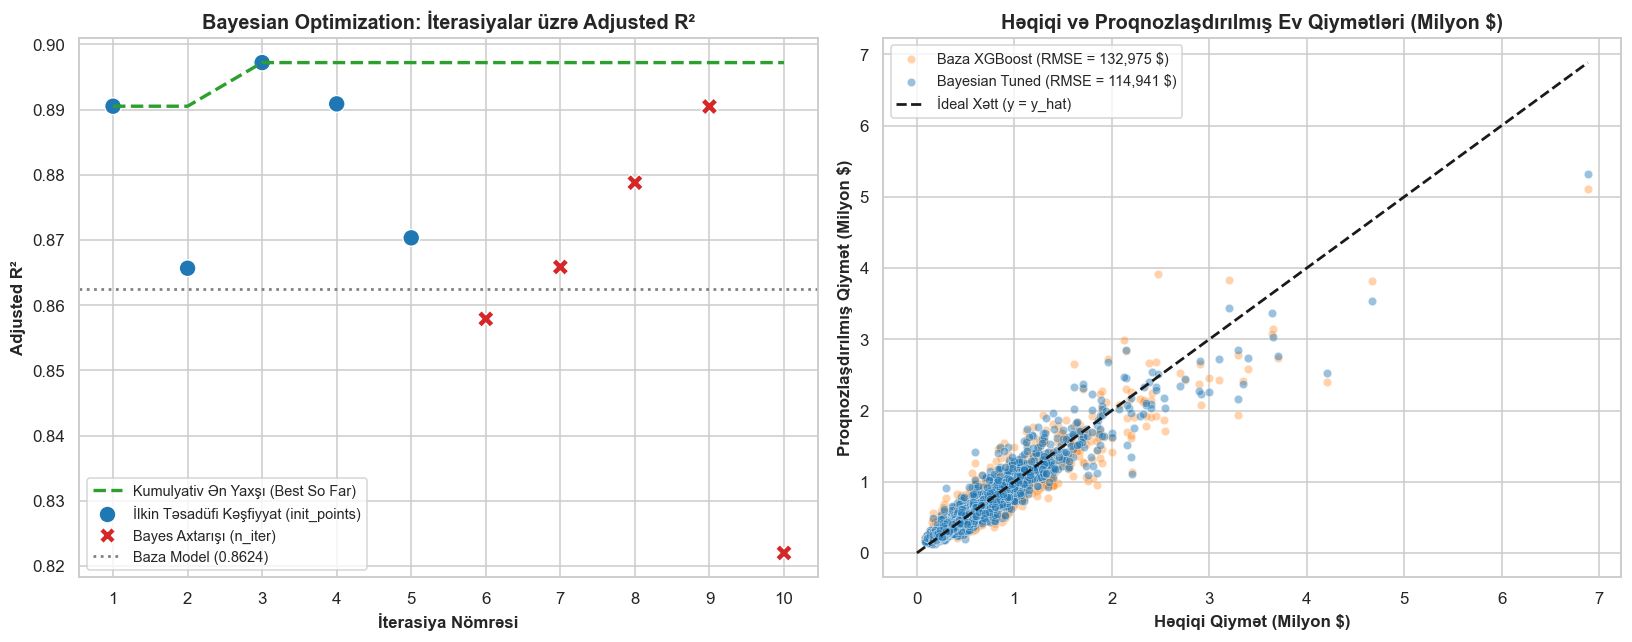

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Sol Qrafik: İterasiyalar üzrə Adjusted R2
sns.lineplot(
    data=history_df, x="Iterasiya", y="Best_So_Far",
    ax=axes[0], color="#2ca02c", linestyle="--", linewidth=2.2,
    label="Kumulyativ Ən Yaxşı (Best So Far)"
)
sns.scatterplot(
    data=history_df, x="Iterasiya", y="Adjusted_R2",
    hue="Mərhələ", style="Mərhələ", s=120, ax=axes[0],
    palette={"İlkin Təsadüfi Kəşfiyyat (init_points)": "#1f77b4", "Bayes Axtarışı (n_iter)": "#d62728"}
)
axes[0].axhline(adj_r2, color="gray", linestyle=":", linewidth=1.8, label=f"Baza Model ({adj_r2:.4f})")
axes[0].set_title("Bayesian Optimization: İterasiyalar üzrə Adjusted R²", fontsize=13, fontweight="bold")
axes[0].set_xlabel("İterasiya Nömrəsi", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Adjusted R²", fontsize=11, fontweight="bold")
axes[0].set_xticks(range(1, len(history_df) + 1))
axes[0].legend(loc="lower left", fontsize=9.5, frameon=True)

# Sağ Qrafik: Həqiqi Qiymət vs Proqnozlaşdırılmış Qiymət (Baza vs Tuned)
sns.scatterplot(
    x=y_test / 1e6, y=pred / 1e6,
    ax=axes[1], alpha=0.35, color="#ff7f0e", s=30,
    label=f"Baza XGBoost (RMSE = {rmse:,.0f} $)"
)
sns.scatterplot(
    x=y_test / 1e6, y=pred_best / 1e6,
    ax=axes[1], alpha=0.45, color="#1f77b4", s=30,
    label=f"Bayesian Tuned (RMSE = {rmse_best:,.0f} $)"
)
max_price = max(y_test.max(), pred_best.max()) / 1e6
axes[1].plot([0, max_price], [0, max_price], "k--", linewidth=1.8, label="İdeal Xətt (y = y_hat)")
axes[1].set_title("Həqiqi və Proqnozlaşdırılmış Ev Qiymətləri (Milyon $)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Həqiqi Qiymət (Milyon $)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Proqnozlaşdırılmış Qiymət (Milyon $)", fontsize=11, fontweight="bold")
axes[1].legend(loc="upper left", fontsize=9.5, frameon=True)

plt.tight_layout()
plt.show()

In [33]:
# 2. Ən Əhəmiyyətli 15 Əlamət (Feature Importance) və Qalıq Xətaların (Residuals) Paylanması
feature_names = pipe_best.named_steps["preprocess"].get_feature_names_out()
clean_names = [name.replace("num__", "").replace("cat__", "") for name in feature_names]
importances = pipe_best.named_steps["model"].feature_importances_

fi_df = (
    pd.DataFrame({"Əlamət": clean_names, "Əhəmiyyətlilik": importances})
    .sort_values("Əhəmiyyətlilik", ascending=False)
    .head(15)
)

fi_df

,Əlamət,Əhəmiyyətlilik
378,grade,0.180201
369,waterfront_False,0.090911
373,sqft_living,0.040868
370,waterfront_True,0.035969
386,sqft_living15,0.028357
384,lat,0.023894
376,view,0.020795
385,long,0.019543
40,date_2014-06-10T22:00:00Z,0.016420
381,yr_built,0.014734


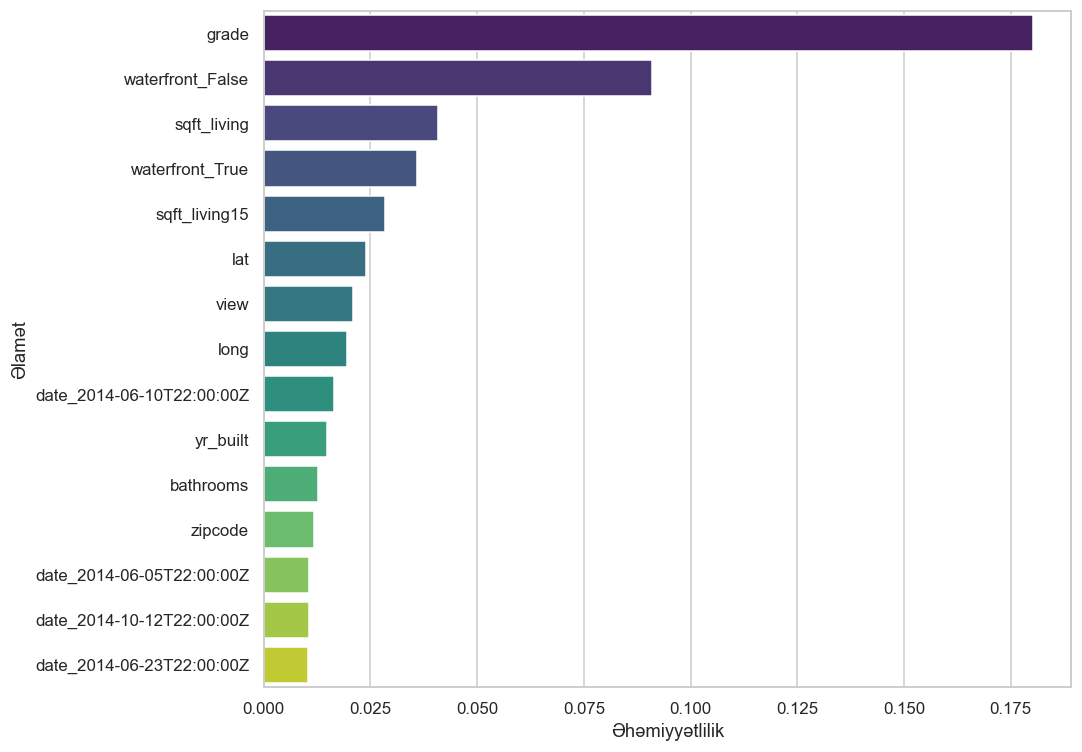

In [36]:
plt.figure(figsize=(10, 7))

# Sol Qrafik: Top 15 Feature Importance
sns.barplot(
    data=fi_df, x="Əhəmiyyətlilik", y="Əlamət", palette="viridis"
)
axes[0].set_title("Bayesian Tuned XGBoost: Ən Əhəmiyyətli 15 Əlamət", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Nisbi Əhəmiyyətlilik (Gain / Importance)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Əlamət (Feature)", fontsize=11, fontweight="bold")

# Sağ Qrafik: Qalıq Xətaların (Residuals = y_test - y_pred) Paylanması
residuals_base = (y_test - pred) / 1e3
residuals_best = (y_test - pred_best) / 1e3

plt.tight_layout()
plt.show()

---

## 8. Metodoloji Mükəmməlləşdirmə: (Feature Engineering) və (Leak-Free) Optimallaşdırma

Yuxarıdakı klassik yanaşmada iki mühüm metodoloji məqamı daha da təkmilləşdirmək mümkündür:

1. **Yüksək Kardinallıqlı `date` Sütununun `OneHotEncoder` ilə Kodlaşdırılması Problemi:**
   * Xam `date` sətirlərini (`'2014-10-12T22:00:00Z'`) birbaşa `OneHotEncoder`-ə ötürdükdə **369 ədəd seyrək (*sparse*) ikili sütun** yaranır və $p_{\text{effective}} = 388$ olur.
   * Bu isə $\text{Adjusted } R^2 = 1 - (1 - R^2)\frac{n-1}{n-p-1}$ düsturunda $p=388$ olduğu üçün modeli lazımsız yerə cərimələyir və ağacların zaman trendini öyrənməsini çətinləşdirir.
   * **Həll:** `date` sütunundan **`sale_year` (satış ili)**, **`sale_month` (satış ayı)**, həmçinin **`house_age` (evin yaşı = `sale_year - yr_built`)** və **`is_renovated` (təmir olunubmu: `0/1`)** əlamətlərini çıxarırıq. Nəticədə əlamət sayı **388-dən 21-ə** düşür!

2. **Test Dəstinin Hiperparametr Seçimindən Tam İzolyasiyası (Data Leakage-in Qarşısının Alınması):**
   * `train_eval` daxilində birbaşa `X_test` üzərində qiymətləndirmə aparmaq test dəstinin məlumatlarını hiperparametr seçiminə sızdırır.
   * **Həll:** Təlim dəstini (`train`) daxildə **Təlim (`X_tr`)** və **Doğrulama (`X_val`)** hissələrinə ayırırıq. Bayes optimallaşdırması yalnız `X_val` üzrə $\text{Adjusted } R^2$-ni maksimallaşdırır, `X_test` isə yalnız ən sonda bir dəfə yoxlanılır.

In [37]:
def engineer_housing_features(data: pd.DataFrame) -> pd.DataFrame:
    """Tarix və tikinti sütunlarından informativ ədədi əlamətlər çıxaran funksiya."""
    d = data.copy()
    dt = pd.to_datetime(d["date"], utc=True)
    d["sale_year"] = dt.dt.year
    d["sale_month"] = dt.dt.month
    d["house_age"] = d["sale_year"] - d["yr_built"]
    d["is_renovated"] = d["yr_renovated"].notna().astype(int)
    d["waterfront"] = d["waterfront"].astype(int)
    return d.drop(columns=["date"])

# Əlamət mühəndisliyinin tətbiqi
train_fe = engineer_housing_features(train)
test_fe  = engineer_housing_features(test)

fe_cols = [c for c in train_fe.columns if c != target]

# Sızmasız (Leak-Free) optimallaşdırma üçün təlim dəstinin Train (80%) və Validation (20%) hissələrinə bölünməsi
X_tr, X_val, y_tr, y_val = train_test_split(
    train_fe[fe_cols], train_fe[target], test_size=0.2, random_state=123
)
X_test_fe, y_test_fe = test_fe[fe_cols], test_fe[target]

print(f"Əvvəlki effektiv əlamət sayı (p_effective): {p_effective}")
print(f"Yeni effektiv əlamət sayı (p_fe):           {len(fe_cols)}")

def train_eval_leak_free(colsample_bytree, subsample, n_estimators, learning_rate, max_depth):
    """Yalnız doğrulama dəsti (X_val) üzərində qiymətləndirmə aparan sızmasız hədəf funksiyası."""
    model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=int(round(n_estimators)),
        learning_rate=learning_rate,
        max_depth=int(round(max_depth)),
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        random_state=123,
        n_jobs=-1
    )
    model.fit(X_tr, y_tr)
    pred_v = model.predict(X_val)
    return adjusted_r2(y_val.values, pred_v, X_tr.shape[1])

optimizer_lf = BayesianOptimization(
    f=train_eval_leak_free,
    pbounds={
        "colsample_bytree": (0.4, 1.0),
        "subsample":        (0.6, 1.0),
        "n_estimators":     (100, 500),
        "learning_rate":    (0.03, 0.25),
        "max_depth":        (4, 9)
    },
    random_state=123,
    verbose=2
)

optimizer_lf.maximize(init_points=5, n_iter=5)

# Tapılmış ən yaxşı hiperparametrlərlə tam təlim dəsti (train_fe) üzərində yekun modelin öyrədilməsi
lf_best = optimizer_lf.max["params"].copy()
final_lf_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=int(round(lf_best["n_estimators"])),
    learning_rate=lf_best["learning_rate"],
    max_depth=int(round(lf_best["max_depth"])),
    subsample=lf_best["subsample"],
    colsample_bytree=lf_best["colsample_bytree"],
    random_state=123,
    n_jobs=-1
)
final_lf_model.fit(train_fe[fe_cols], train_fe[target])
pred_lf_test = final_lf_model.predict(X_test_fe)

r2_lf   = r2_score(y_test_fe, pred_lf_test)
adj_lf  = adjusted_r2(y_test_fe.values, pred_lf_test, len(fe_cols))
mae_lf  = mean_absolute_error(y_test_fe, pred_lf_test)
rmse_lf = np.sqrt(mean_squared_error(y_test_fe, pred_lf_test))

print("\n=== Sızmasız (Leak-Free) + Əlamət Mühəndisliyi Modelinin Test Nəticələri ===")
print(f"R2:          {r2_lf:.4f}")
print(f"Adjusted R2: {adj_lf:.4f} (p = {len(fe_cols)} əlamət ilə)")
print(f"MAE:         {mae_lf:,.2f} $")
print(f"RMSE:        {rmse_lf:,.2f} $")

Əvvəlki effektiv əlamət sayı (p_effective): 388
Yeni effektiv əlamət sayı (p_fe):           22
|   iter    |  target   | colsam... | subsample | n_esti... | learni... | max_depth |
-------------------------------------------------------------------------------------
| 1         | 0.9022767 | 0.8178815 | 0.7144557 | 190.74058 | 0.1512892 | 7.5973448 |
| 2         | 0.9027975 | 0.6538638 | 0.9923056 | 373.93189 | 0.1358050 | 5.9605875 |
| 3         | 0.9010516 | 0.6059068 | 0.8916198 | 275.42889 | 0.0431291 | 5.9902212 |
| 4         | 0.8939915 | 0.8427972 | 0.6729966 | 170.18070 | 0.1469413 | 6.6591379 |
| 5         | 0.8938759 | 0.7806405 | 0.9397727 | 389.78212 | 0.1644251 | 7.6122169 |
| 6         | 0.8969424 | 0.7260829 | 0.8254500 | 190.79486 | 0.1536230 | 7.7033065 |
| 7         | 0.8891973 | 0.5842885 | 0.7934483 | 339.59572 | 0.1692306 | 8.1662705 |
| 8         | 0.8975956 | 0.5879733 | 0.6856201 | 498.58715 | 0.1123474 | 4.4976620 |
| 9         | 0.8809786 | 0.5525525 | 0.71201